## Emotion Classification with RNNs, LSTms, & GRUs

Classifying text into 6 emotions (sadness, joy, love, anger, fear, suprise) by comparing plain recurrent models before building an **Advanced Bidirectional GRU**

### Import Libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
%pip install datasets

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# Dataset load
from datasets import load_dataset

C:\Users\hp\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Load Dataset

Load the dair-ai/emotion dataset from Hugging Face

In [4]:
emotion_dataset = load_dataset('dair-ai/emotion')
train_text = emotion_dataset['train']['text']
train_label = emotion_dataset['train']['label']

test_text = emotion_dataset['test']['text']
test_label = emotion_dataset['test']['label']

In [5]:
label_names = emotion_dataset['train'].features['label'].names

In [7]:
df_train = pd.DataFrame(
    {
        'text' : train_text,
        'label' : [label_names[i] for i in train_label]
    }
)

df_test = pd.DataFrame(
    {
        'text' : test_text,
        'label' : [label_names[i] for i in test_label]
    }
)

In [8]:
df_train.head()

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


### Exploratory Data Analysis (EDA)


Visualize class distribution across the 6 emotion labels. 

In [9]:
df_train['label'].value_counts()

label
joy         5362
sadness     4666
anger       2159
fear        1937
love        1304
surprise     572
Name: count, dtype: int64

<Axes: xlabel='label', ylabel='count'>

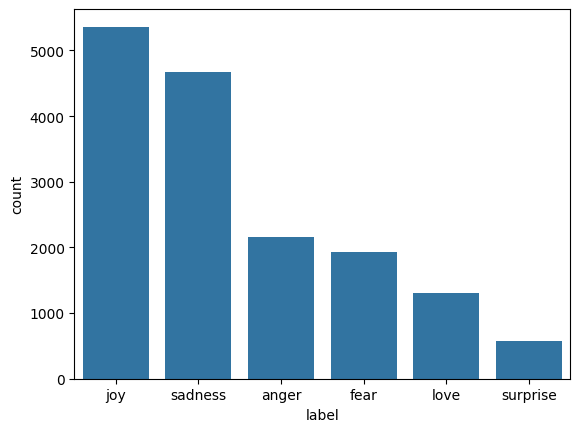

In [10]:
sns.countplot(x='label', data=df_train, order=df_train['label'].value_counts().index)

### Data Preprocessing - Using NLP

Tokenize text, pad sequences to max length 50, and convert labels to NumPy arrays.

In [ ]:
# !pip install tensorflow

Defaulting to user installation because normal site-packages is not writeable
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached wheel-0.48.0-py3-none-any.whl.metadata (2.3 kB)
   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.5/351.2 MB 1.7 MB/s eta 0:03:24
   ---------------------------------------- 1.0/351.2 MB 1.8 MB/s eta 0:03:14
   ---------------------------------------- 1.3/351.2 MB 1.6 MB/s eta 0:03:44
   ---------------------------------------- 1.6/351.2 MB 1.5 MB/s eta 0:03:47
   ---------------------------------------- 1.8/351.2 MB 1.5 MB/s eta 0:03:50
   ---------------------------------------- 2.4/351.2 MB 1.6 MB/s eta 0:03:37
   ---------------------------------------- 2.4/351.2 MB 1.6 MB/s eta 0:03:37
   ---------------------------------------- 2.9/351.2 MB 1.6 MB/s eta 0:03:44
   -------------


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_words = 10000

tokenizer = Tokenizer(num_words = max_words, oov_token = '<unk')
tokenizer.fit_on_texts(df_train['text'])

train_sequence = tokenizer.texts_to_sequences(df_train['text'])
test_sequence = tokenizer.texts_to_sequences(df_test['text'])

padded_train_sequence = pad_sequences(train_sequence, maxlen=50, padding='post', truncating='post')
padded_test_sequence = pad_sequences(test_sequence, maxlen=50, padding='post', truncating='post')

padded_train_sequence


train_labels = np.array(train_label)
test_labels = np.array(test_label)

num_classes = len(np.unique(train_labels))
num_classes

print(f"Vocabulary Size: {len(tokenizer.word_index)}")
print((f"Max Sentence Length: {padded_train_sequence.shape[1]}"))


Vocabulary Size: 15213
Max Sentence Length: 50
